# Timestep convergence verification

This notebook investigates the chosen default MD timestep $1/20\Omega$ on whether it provides the sufficient accuracy. It is tested by comparing the convergence in equilibrium positions, overall simulated trajectory and frequency peaks from a single ion oscillation in the same setup with varying timesteps. 

We use two independent simulations:

- **Short trajectory (1 µs):** comparison at identical physical times, reference refinement and empirical convergence order.
- **Long trajectory (100 µs):** accumulated trajectory discrepancy and consistency of the dominant secular spectral peaks. The `long` sweep is computationally expensive; run it separately when needed.

In [22]:
from pathlib import Path
import contextlib, hashlib, json, math, time
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import constants as ct
from scipy.signal import periodogram

import sion as sn
import sion.pylion as pl

ROOT = Path.cwd() / "supplementary" / "sion_timestep_verification"
ROOT.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 200, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})

## 1. Trap configuration

Trap configuration, used for this convergence test.

In [23]:
L = 1e-6
Vrf = 200.0
Omega = 2 * np.pi * 40e6              
M = 40 * ct.atomic_mass
Z = ct.elementary_charge
Urf = Vrf * np.sqrt(Z/M) / (2*L*Omega)

top_dc = [[300, 1000]] * 3
bottom_dc = top_dc
top_rf, bottom_rf = [6000, 200], [12000, 120]
central_dc, gap = [12000, 150], 0
rf_set = [Vrf, Vrf]
omegas = [Omega, Omega]

DC_VOLTAGES_OVERRIDE = None  # Or seven voltages optimized for THIS configuration

s, RF_coordinates, DC_coordinates = sn.five_wire_trap_design(
    Urf, top_dc, bottom_dc, top_rf, bottom_rf, central_dc,
    gap=gap, need_coordinates=True, need_plot=False,
)
if DC_VOLTAGES_OVERRIDE is None:
    x0 = s.minimum([0, 0, 82.45], axis=(0, 1, 2),
                   coord=np.identity(3), method="Newton-CG",
                   options={"maxiter": 1000000})
    print(f'RF potential minimum: {x0}')
    initial_dc = 2 * np.array([-0.15, 6, -10, 6, 10, -6, 10], dtype=float)
    dc_set = sn.position_optimization(
        s, [[x0[0], x0[1], x0[2]]], initial_dc,
        eps=1e-2, tol=1e-36, numbers=0, ion_masses=M, charges=1,
        callback_num=100, voltage_bounds=(-20, 20),
    )
else:
    dc_set = DC_VOLTAGES_OVERRIDE

dc_set = np.asarray(dc_set, dtype=float)
assert dc_set.shape == (7,) and np.isfinite(dc_set).all()
assert len(RF_coordinates) == len(rf_set)
assert len(DC_coordinates) == len(dc_set)
print("RF frequency:", Omega/(2*np.pi*1e6), "MHz")
print("Optimized DC voltages [V]:", dc_set)

RF potential minimum: [ 3.64592246e-19 -5.86481686e+01  1.28325866e+02]
Initial loss = 168.00242434592178


Optimizing voltages: 34it [00:03,  8.60it/s]

Final loss = 2.4150508399960068e-05
Final uset = [np.float64(1.3743830864478217), np.float64(11.714833344285832), np.float64(-19.92645212677468), np.float64(11.712108592372559), np.float64(18.892328158688706), np.float64(-12.81670365619332), np.float64(18.892666631837603)]
RF frequency: 40.00000000000001 MHz
Optimized DC voltages [V]: [  1.37438309  11.71483334 -19.92645213  11.71210859  18.89232816
 -12.81670366  18.89266663]


## 2. Simulation parameters

All simulation runs are the same, except for the timestep value. By default there is no cooling for the full trajectroy inspection over 100 us. `USE_LANGEVIN` to use cooling.

Let $h_0=1/(20\Omega)$ denote the default SION timestep. The code tests $h=(K/8)h_0$. All trajectories are dumped at an identical physical-time grid, so no trajectory interpolation or RF-phase mismatch is introduced by the comparison.


In [24]:
ION_SPECIES = {"mass": 40, "charge": 1}
ION_POSITIONS_M = np.array([[5e-6, -50e-6, 135e-6]], dtype=float)
USE_LANGEVIN = False
LANGEVIN_ARGS = (0, 5e-6)  # Used only when USE_LANGEVIN=True

SHORT_DURATION_S = 1e-6
LONG_DURATION_S = 100e-6
SHORT_K = (1, 2, 4, 8, 12, 16, 24, 32, 64)
LONG_K = (1, 2, 4, 8, 12, 16, 24, 32, 64)      # 0.5, 1, 2, 4 x the original timestep
SHORT_REFERENCE_K = 1
LONG_REFERENCE_K = 1
DEFAULT_K = 8

RUN_SHORT = False
RUN_LONG = False                # Change to False to run short verification only
SKIP_EXISTING = True
MPI_PROCESSES = 1
OMP_THREADS = 1

h0 = 1 / (20 * Omega)
h_unit = h0 / 8
rf_period = 2*np.pi / Omega
ALL_K = sorted(set(SHORT_K + LONG_K))
COMMON_K = math.lcm(*ALL_K)  # exact integer output-grid alignment
dump_interval = COMMON_K * h_unit

def run_plan(k, requested_duration):
    n_frames = math.ceil(requested_duration/dump_interval)
    dump_every = COMMON_K // k
    return int(n_frames*dump_every), int(dump_every), n_frames*dump_interval

print(f"Default timestep h0: {h0*1e9:.5f} ns")
print(f"Finest timestep: {h_unit*1e9:.5f} ns")
print(f"RF period: {rf_period*1e9:.3f} ns, output interval: {dump_interval*1e9:.3f} ns")
print(f"Nominal Fourier resolution for 100 µs: ~{1/LONG_DURATION_S/1e3:g} kHz")
display(pd.DataFrame([
    {"K": k, "h/h0": k/8, "h (ns)": k*h_unit*1e9,
     "short steps": run_plan(k, SHORT_DURATION_S)[0],
     "long steps": run_plan(k, LONG_DURATION_S)[0] if k in LONG_K else None}
    for k in ALL_K
]).round(5))

Default timestep h0: 0.19894 ns
Finest timestep: 0.02487 ns
RF period: 25.000 ns, output interval: 4.775 ns
Nominal Fourier resolution for 100 µs: ~10 kHz


,K,h/h0,h (ns),short steps,long steps
0,1,0.125,0.02487,40320,4021248
1,2,0.250,0.04974,20160,2010624
2,4,0.500,0.09947,10080,1005312
3,8,1.000,0.19894,5040,502656
4,12,1.500,0.29842,3360,335104
5,16,2.000,0.39789,2520,251328
6,24,3.000,0.59683,1680,167552
7,32,4.000,0.79577,1260,125664
8,64,8.000,1.59155,630,62832


## 3. Simulation config

All case files are placed in a configuration-specific directory. LAMMPS stdout is saved in case a run fails. Raw position dumps retain the precision of the installed SION/LAMMPS dump writer (1 nm): this is relevant to interpretation near the ~1 nm scale.

In [25]:
CONFIG = {
    "Omega": float(Omega), "rf_set": list(map(float, rf_set)),
    "dc_set": dc_set.tolist(),
    "rf_electrodes": repr(RF_coordinates), "dc_electrodes": repr(DC_coordinates),
    "ions": ION_SPECIES, "ion_positions_m": ION_POSITIONS_M.tolist(),
    "langevin": list(LANGEVIN_ARGS) if USE_LANGEVIN else None,
    "short_duration_s": SHORT_DURATION_S, "long_duration_s": LONG_DURATION_S,
    "short_k": SHORT_K, "long_k": LONG_K,
    "mpi": MPI_PROCESSES, "omp": OMP_THREADS, "common_k": COMMON_K,
}
case_id = hashlib.sha256(json.dumps(CONFIG, sort_keys=True).encode()).hexdigest()[:12]
OUT = ROOT / case_id
OUT.mkdir(parents=True, exist_ok=True)
(OUT / "configuration.json").write_text(json.dumps(CONFIG, indent=2), encoding="utf-8")


def simulate(sweep, k, duration):
    """Run a single full-RF trajectory; a successful existing case can be reused."""
    folder = OUT / sweep
    folder.mkdir(exist_ok=True)
    dump_path = folder / f"positions_k{k}.txt"
    record_path = folder / f"case_k{k}.json"
    stdout_path = folder / f"run_k{k}.log"
    if SKIP_EXISTING and record_path.exists() and dump_path.exists():
        saved = json.loads(record_path.read_text(encoding="utf-8"))
        if saved.get("status") == "ok":
            return saved

    steps, stride, duration_actual = run_plan(k, duration)
    dt = k*h_unit
    sim_name = (folder / f"sim_k{k}").relative_to(Path.cwd())
    sim = pl.Simulation(str(sim_name))
    sim.append(pl.placeions(ION_SPECIES, ION_POSITIONS_M.tolist()))
    sim.append(sn.polygon_trap(omegas, rf_set, dc_set, RF_coordinates,
                               DC_coordinates, timestep=float(dt)))
    if USE_LANGEVIN:
        sim.append(pl.langevinbath(*LANGEVIN_ARGS))
    sim.append(pl.dump(str(dump_path), variables=["x", "y", "z"], steps=stride))
    sim.append(pl.evolve(steps))

    sim.attrs["timestep"] = float(dt)     # after all instructions
    assert np.isclose(float(sim.attrs["timestep"]), dt, rtol=1e-14, atol=0)
    record = {"status": "failed", "K": k, "dt_s": dt, "steps": steps,
              "duration_s": duration_actual, "dump_path": str(dump_path),
              "log_path": str(stdout_path)}
    try:
        with stdout_path.open("w", encoding="utf-8") as log:
            with contextlib.redirect_stdout(log), contextlib.redirect_stderr(log):
                start = time.perf_counter()
                sim.execute(mpi_processes=MPI_PROCESSES, omp_threads=OMP_THREADS)
                record["wall_time_s"] = time.perf_counter()-start
        record["status"] = "ok"
    except Exception:
        import traceback
        record["error"] = traceback.format_exc()
        print(record["error"])
    record_path.write_text(json.dumps(record, indent=2), encoding="utf-8")
    if record["status"] != "ok":
        raise RuntimeError(f"Simulation failed. Inspect {stdout_path}")
    return record


def sweep_runs(name, k_values, duration):
    records = {}
    for k in k_values:
        nsteps, _, _ = run_plan(k, duration)
        print(f"{name}: K={k:2d}, h/h0={k/8:g}, steps={nsteps:,}", flush=True)
        records[k] = simulate(name, k, duration)
    return records

print("Result directory:", OUT)

Result directory: c:\Users\User\Desktop\ARTEM\Sion\tests\supplementary\sion_timestep_verification\7d113492efb7


## 4. Trajectory analysis

For ion $i$ and common output time $t_j$, define $\delta\mathbf r_{ij}(h)=\mathbf r_{ij}(h)-\mathbf r_{ij}(h_{\rm ref})$. Both trajectories have the same initial state and are evaluated at identical times.

We report the RMS Euclidean position discrepancy:

$$
E_{\rm RMS}(h)=\left[\frac{1}{N_tN_i}\sum_{j=1}^{N_t}\sum_{i=1}^{N_i}\left\|\delta\mathbf r_{ij}(h)\right\|_2^2\right]^{1/2},
$$

and the maximum instantaneous position discrepancy:

$$
E_{\max}(h)=\max_{i,j}\left\|\delta\mathbf r_{ij}(h)\right\|_2.
$$

These are spatial errors in nm, sensitive to both secular-trajectory and RF-phase differences. A growing phase offset can produce a large pointwise RMSE even when both simulations remain bounded.

In [26]:
def load_xyz(record):
    """Read positions and convert LAMMPS step indices to common output-frame IDs."""
    steps, xyz = pl.readdump(record["dump_path"])
    steps = np.asarray(steps, dtype=np.int64).reshape(-1)
    xyz = np.asarray(xyz, dtype=float)
    if xyz.ndim != 3 or xyz.shape != (len(steps), len(ION_POSITIONS_M), 3):
        raise ValueError(f"Unexpected dump array shape: {xyz.shape}")
    if not np.isfinite(xyz).all():
        raise ValueError("Non-finite coordinates")
    ticks = steps * int(record["K"])
    if np.any(ticks % COMMON_K != 0):
        raise ValueError("Output timestamps are not on the common time grid")
    frames = ticks // COMMON_K
    if len(frames) < 4 or not np.all(np.diff(frames) == 1):
        raise ValueError("Missing or nonconsecutive output frames")
    expected_last = round(record["duration_s"]/dump_interval)
    if frames[-1] != expected_last:
        raise ValueError("Missing final trajectory frame")
    return frames, xyz


def trajectory_difference(record, reference):
    ref_frames, ref_xyz = load_xyz(reference)
    frames, xyz = load_xyz(record)
    if not np.array_equal(frames, ref_frames):
        raise ValueError("Trajectories have different output times")
    return xyz - ref_xyz


def trajectory_table(records, reference_k):
    rows = []
    for k, record in sorted(records.items()):
        delta = trajectory_difference(record, records[reference_k])
        spatial_distance = np.linalg.norm(delta, axis=2)  # shape: time x ion
        rows.append({
            "K": k, "h/h0": k/8, "h (ns)": record["dt_s"]*1e9,
            "RMS distance (nm)": 1e9*np.sqrt(np.mean(spatial_distance**2)),
            "Max distance (nm)": 1e9*np.max(spatial_distance),
            "Component RMSE (nm)": 1e9*np.sqrt(np.mean(delta**2)),
            "Final distance (nm)": 1e9*np.max(spatial_distance[-1]),
            "Duration (µs)": record["duration_s"]*1e6,
            "Wall time (s)": record["wall_time_s"],
        })
    return pd.DataFrame(rows)


def observed_order(records):
    """p=log2[D(2h,4h)/D(h,2h)] for consecutive step doublings."""
    rows = []
    for k in sorted(records):
        if 2*k not in records or 4*k not in records:
            continue
        d_fine = trajectory_difference(records[k], records[2*k])
        d_coarse = trajectory_difference(records[2*k], records[4*k])
        a = np.sqrt(np.mean(np.sum(d_fine**2, axis=2)))
        b = np.sqrt(np.mean(np.sum(d_coarse**2, axis=2)))
        rows.append({"h/h0": k/8, "2h/h0": k/4, "4h/h0": k/2,
                     "D(h,2h) (nm)": a*1e9, "D(2h,4h) (nm)": b*1e9,
                     "Observed order p": np.log2(b/a) if a > 0 and b > 0 else np.nan})
    return pd.DataFrame(rows)

## 5. Short sweep

Reference value -- the shortest timestep: $h_{\rm ref}=h_0/8$. The $h_0/4$ result provides a direct reference-refinement check. The pairwise convergence order is computed without treating this finest trajectory as exact:

$$ p=\log_2\!\left[\frac{D(2h,4h)}{D(h,2h)}\right], \qquad
D(a,b)=\operatorname{RMS}_{i,j}\|\mathbf r_{ij}(a)-\mathbf r_{ij}(b)\|_2. $$

A slope near $p=2$ supports second-order convergence over the tested range, subject to a sufficiently smooth trajectory and the precision of recorded positions.

In [27]:
if RUN_SHORT:
    short_records = sweep_runs("short", SHORT_K, SHORT_DURATION_S)
else:
    OUT = ROOT / "7d113492efb7"
    short_records = {k: json.loads((OUT/"short"/f"case_k{k}.json").read_text())
                     for k in SHORT_K}

short_results = trajectory_table(short_records, SHORT_REFERENCE_K)
order_results = observed_order(short_records)
display(short_results[["h/h0", "h (ns)", "RMS distance (nm)",
                       "Max distance (nm)", "Final distance (nm)"]].round(3))
display(order_results.round(3))
short_results.to_csv(OUT/"short_trajectory_convergence.csv", index=False)
order_results.to_csv(OUT/"observed_convergence_order.csv", index=False)

refinement = short_results.loc[short_results.K.eq(2)].iloc[0]
print(f"Reference refinement h0/8 -> h0/4: "
      f"RMS 3D discrepancy = {refinement['RMS distance (nm)']:.3f} nm, "
      f"maximum = {refinement['Max distance (nm)']:.3f} nm")

# An application-level tolerance, NOT a guaranteed absolute integrator error.
POSITION_TOLERANCE_NM = 1.0
if refinement["RMS distance (nm)"] <= POSITION_TOLERANCE_NM:
    print("Reference-refinement discrepancy is within the 1 nm analysis tolerance; "
          "check whether the result is limited by dump precision.")
else:
    print("Reference-refinement discrepancy exceeds 1 nm. "
          "Avoid claiming an absolute 1 nm integration accuracy.")
if not order_results.empty:
    print("Observed orders p:", order_results["Observed order p"].round(3).tolist())

,h/h0,h (ns),RMS distance (nm),Max distance (nm),Final distance (nm)
0,0.125,0.025,0.000,0.000,0.000
1,0.250,0.050,0.618,1.487,1.300
2,0.500,0.099,2.698,6.676,6.676
3,1.000,0.199,11.303,27.777,27.777
4,1.500,0.298,25.656,63.138,63.138
5,2.000,0.398,45.780,112.604,112.604
6,3.000,0.597,103.334,253.950,253.950
7,4.000,0.796,184.092,452.090,452.090
8,8.000,1.592,742.533,1812.119,1810.101


,h/h0,2h/h0,4h/h0,"D(h,2h) (nm)","D(2h,4h) (nm)",Observed order p
0,0.125,0.25,0.5,0.618,2.184,1.821
1,0.250,0.50,1.0,2.184,8.643,1.984
2,0.500,1.00,2.0,8.643,34.486,1.996
3,1.000,2.00,4.0,34.486,138.320,2.004
4,2.000,4.00,8.0,138.320,558.842,2.014


Reference refinement h0/8 -> h0/4: RMS 3D discrepancy = 0.618 nm, maximum = 1.487 nm
Reference-refinement discrepancy is within the 1 nm analysis tolerance; check whether the result is limited by dump precision.
Observed orders p: [1.821, 1.984, 1.996, 2.004, 2.014]


### Short trajectory convergence

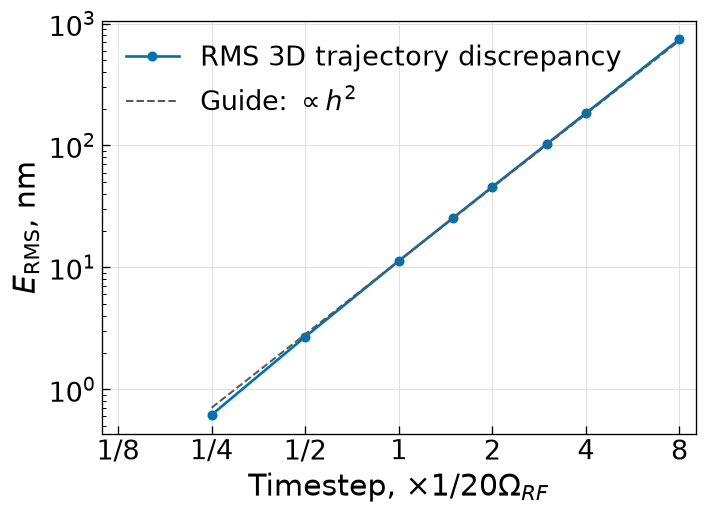

In [28]:
from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator, NullFormatter

# Label only octave-spaced timesteps; intermediate simulated points are retained.
h_ticks = [1/8, 1/4, 1/2, 1, 2, 4, 8]
h_labels = [r"$1/8$", r"$1/4$", r"$1/2$", r"$1$", r"$2$", r"$4$", r"$8$"]

def format_convergence_axis(ax):
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.xaxis.set_major_locator(FixedLocator(h_ticks))
    ax.xaxis.set_major_formatter(FixedFormatter(h_labels))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_xlim(1/8 / 1.13, 8 * 1.13)
    ax.set_xlabel(r"Timestep, $\times 1/20\Omega_{RF}$", fontsize=18)
    ax.tick_params(axis="both", which="major", labelsize=16, direction="in", length=5)
    ax.tick_params(axis="y", which="minor", direction="in", length=2.5)
    ax.grid(False, which="both")
    ax.grid(True, which="major", axis="both", color="0.88", linewidth=0.6, alpha=1)
    ax.set_axisbelow(True)

short_plot = short_results.loc[short_results.K.ne(SHORT_REFERENCE_K)].sort_values("K")
x = short_plot["h/h0"].to_numpy()
y = short_plot["RMS distance (nm)"].to_numpy()
positive = y > 0

fig, ax = plt.subplots(figsize=(6, 4.4))
ax.plot(x[positive], y[positive], "o-", color="#0072B2", lw=1.6, ms=5,
        label="RMS 3D trajectory discrepancy")
# Guide to the eye only; not a fitted convergence law.
base = short_plot.loc[short_plot.K.eq(DEFAULT_K), "RMS distance (nm)"]
if len(base) and base.iloc[0] > 0:
    ax.plot(x, base.iloc[0]*x**2, "--", color="0.35", lw=1.2,
            label=r"Guide: $\propto h^2$")
format_convergence_axis(ax)
ax.set_ylabel(r"$E_{\mathrm{RMS}}$, nm", fontsize=18)
ax.legend(frameon=False, fontsize=16)
fig.tight_layout()
fig.savefig(OUT/"figure_short_convergence.eps", bbox_inches="tight")
plt.show()

## 6. Long sweep

For long (100 us) sweep we calculate both trajectory discrepancy and secular frequencies from the FFT of the resulting trajectory.
For each Cartesian coordinate we find the dominant spectral peak in a fixed, sub-RF band. The same axis is compared between timesteps. 

**Long run WARNING: took 3 hours for me**

In [29]:
def dominant_frequency(x, f_sample, f_range_mhz=(0.05, 12.0)):
    """Peak of Hann-windowed, linearly detrended spectrum; log-parabolic refinement."""
    f, power = periodogram(x, fs=f_sample, window="hann", detrend="linear",
                          scaling="spectrum")
    indices = np.flatnonzero((f >= f_range_mhz[0]*1e6) &
                             (f <= f_range_mhz[1]*1e6))
    if len(indices) < 3:
        raise ValueError("Frequency band is empty")
    peak = int(indices[np.argmax(power[indices])])
    if peak <= 0 or peak >= len(f)-1 or power[peak] <= 0:
        return np.nan
    a, b, c = np.log(np.maximum(power[peak-1:peak+2], np.finfo(float).tiny))
    denom = a - 2*b + c
    shift = 0.5*(a-c)/denom if denom < 0 else 0.0
    return float(f[peak] + np.clip(shift, -0.5, 0.5)*(f[1]-f[0]))


def frequency_table(records, reference_k):
    rows = []
    for k, rec in sorted(records.items()):
        frames, xyz = load_xyz(rec)
        sampling_rate = 1/dump_interval
        for ion in range(xyz.shape[1]):
            for axis, name in enumerate("xyz"):
                peak = dominant_frequency(xyz[:, ion, axis], sampling_rate)
                rows.append({"K": k, "h/h0": k/8, "ion": ion, "axis": name,
                             "peak (MHz)": peak/1e6})
    df = pd.DataFrame(rows)
    ref = df[df.K.eq(reference_k)].set_index(["ion", "axis"])["peak (MHz)"]
    df["shift from ref (kHz)"] = [
        1e3*(row["peak (MHz)"]-ref[(row["ion"], row["axis"])])
        for _, row in df.iterrows()
    ]
    return df


if RUN_LONG:
    long_records = sweep_runs("long", LONG_K, LONG_DURATION_S)
else:
    long_records = {k: json.loads((OUT/"long"/f"case_k{k}.json").read_text())
                    for k in LONG_K}

long_results = trajectory_table(long_records, LONG_REFERENCE_K)
frequency_results = frequency_table(long_records, LONG_REFERENCE_K)
display(long_results[["h/h0", "RMS distance (nm)", "Max distance (nm)",
                      "Final distance (nm)"]].round(2))
display(frequency_results.round(4))
long_results.to_csv(OUT/"long_trajectory_convergence.csv", index=False)
frequency_results.to_csv(OUT/"long_secular_peaks.csv", index=False)

,h/h0,RMS distance (nm),Max distance (nm),Final distance (nm)
0,0.12,0.00,0.00,0.00
1,0.25,53.19,140.66,50.21
2,0.50,265.89,703.57,232.43
3,1.00,1114.27,2937.67,650.70
4,1.50,2504.90,6520.07,331.18
5,2.00,4351.96,11225.73,2701.58
6,3.00,8419.65,19062.39,15880.85
7,4.00,10128.98,19406.68,12188.34
8,8.00,9196.09,19304.47,5673.33


,K,h/h0,ion,axis,peak (MHz),shift from ref (kHz)
0,1,0.125,0,x,1.5392,0.0000
1,1,0.125,0,y,2.7444,0.0000
2,1,0.125,0,z,4.0693,0.0000
3,2,0.250,0,x,1.5392,-0.0001
4,2,0.250,0,y,2.7445,0.0209
5,2,0.250,0,z,4.0693,0.0175
6,4,0.500,0,x,1.5392,-0.0005
7,4,0.500,0,y,2.7446,0.1041
8,4,0.500,0,z,4.0694,0.0875
9,8,1.000,0,x,1.5392,-0.0020


### Long sweep convergence results

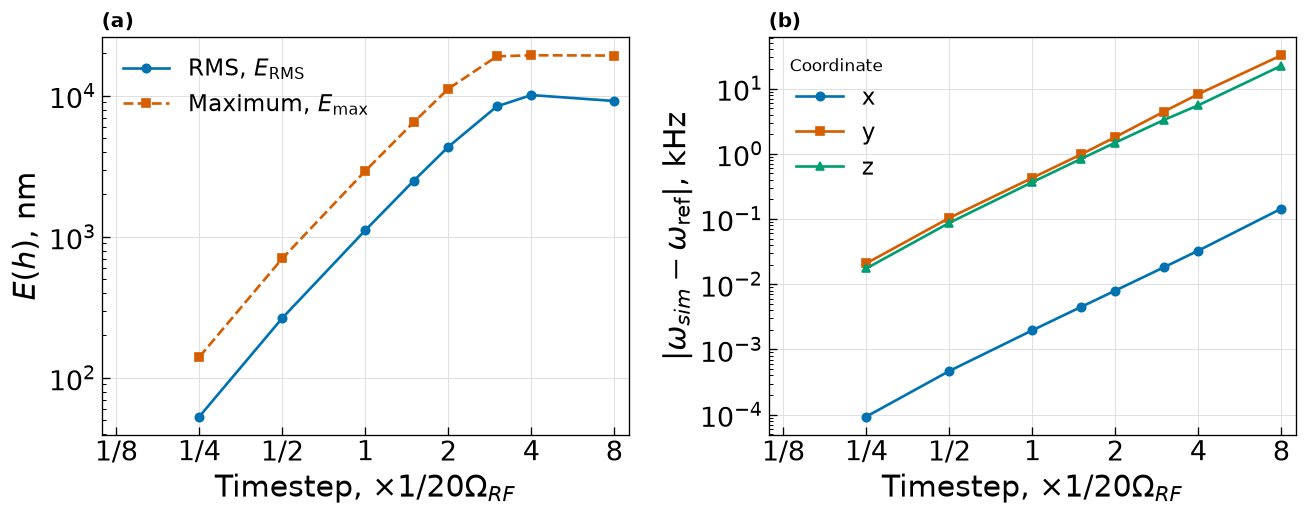

In [30]:
# Both trajectory discrepancies and frequency shifts use h_ref = h0/8.
# The reference itself has zero discrepancy and cannot appear on a log y-axis.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
long_plot = long_results.loc[long_results.K.ne(LONG_REFERENCE_K)].sort_values("K")

for column, marker, style, color, label in [
    ("RMS distance (nm)", "o", "-", "#0072B2", r"RMS, $E_{\mathrm{RMS}}$"),
    ("Max distance (nm)", "s", "--", "#D55E00", r"Maximum, $E_{\max}$"),
]:
    y = long_plot[column].to_numpy()
    axes[0].plot(long_plot["h/h0"], np.where(y > 0, y, np.nan),
                 marker=marker, linestyle=style, color=color, lw=1.6, ms=5,
                 label=label)
format_convergence_axis(axes[0])
axes[0].set_ylabel(r"$E(h)$, nm", fontsize=18)
axes[0].legend(frameon=False, fontsize=14)

for axis, marker, color in zip("xyz", ["o", "s", "^"], ["#0072B2", "#D55E00", "#009E73"]):
    selection = frequency_results.loc[(frequency_results.ion.eq(0)) &
                                      (frequency_results.axis.eq(axis)) &
                                      (frequency_results.K.ne(LONG_REFERENCE_K))].sort_values("K")
    shift = selection["shift from ref (kHz)"].abs().to_numpy()
    axes[1].plot(selection["h/h0"], np.where(shift > 0, shift, np.nan),
                 marker=marker, color=color, lw=1.6, ms=5, label=axis)
format_convergence_axis(axes[1])
axes[1].set_ylabel(r"$|\omega_{sim}-\omega_{\mathrm{ref}}|$, kHz", fontsize=18)
axes[1].legend(title="Coordinate", frameon=False, fontsize=14)

for ax, label in zip(axes, ["(a)", "(b)"]):
    ax.set_title(label, loc="left", fontsize=12, fontweight="bold")
fig.tight_layout(w_pad=2.0)
fig.savefig(OUT/"figure_long_convergence.eps", bbox_inches="tight")
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


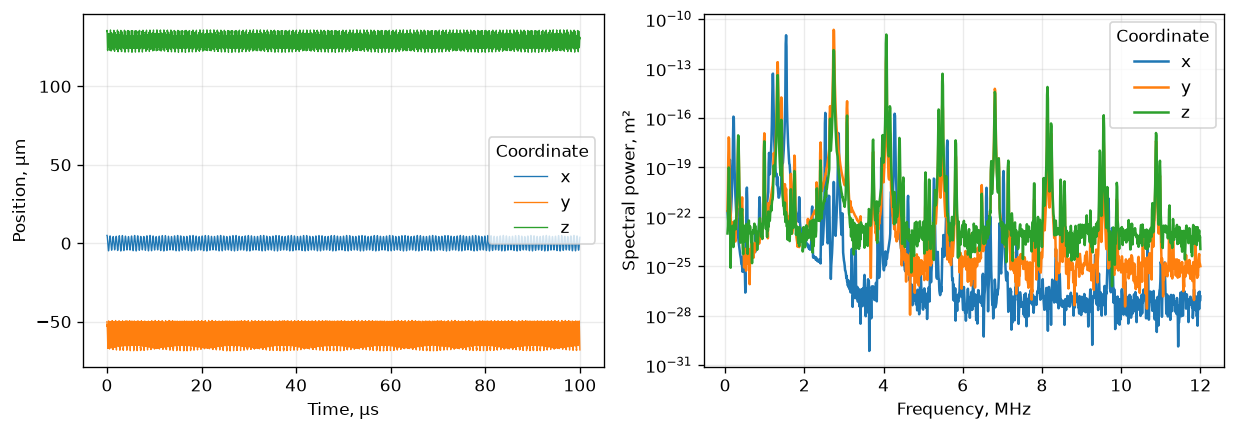

In [31]:
# Optional diagnostic — inspect reference spectrum to confirm that each "dominant" peak
# is genuinely a resolved, excited secular oscillation (rather than a harmonic).
reference_frames, reference_xyz = load_xyz(long_records[LONG_REFERENCE_K])
t_us = reference_frames * dump_interval * 1e6
fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.7))
for axis, name in enumerate("xyz"):
    signal_um = reference_xyz[:, 0, axis]*1e6
    axes[0].plot(t_us, signal_um, label=name, linewidth=0.8)
    freq, power = periodogram(reference_xyz[:, 0, axis], fs=1/dump_interval,
                              window="hann", detrend="linear", scaling="spectrum")
    keep = (freq >= 0.05e6) & (freq <= 12e6)
    axes[1].semilogy(freq[keep]/1e6, np.maximum(power[keep], 1e-40), label=name)
axes[0].set(xlabel="Time, µs", ylabel="Position, µm")
axes[1].set(xlabel="Frequency, MHz", ylabel="Spectral power, m²")
axes[0].legend(title="Coordinate")
axes[1].legend(title="Coordinate")
fig.tight_layout()
fig.savefig(OUT/"diagnostic_long_reference_spectrum.eps", bbox_inches="tight")
plt.show()